### 역할 정의

In [1]:
# 이번에 만들 애플리케이션에서는 답변을 생성하기 전에 답변을 담당할 역할을 선택하는 처리 단계가 있다.
# 여기서는 미리 정의된 역할을 LLM에게 선택하도록 할 것
ROLES = {
    "1": {
        "name": "일반 지식 전문가",
        "description": "폭넓은 분야의 일반적인 질문에 답변",
        "details": "폭넓은 분야의 일반적인 질문에 대해 정확하고 이해하기 쉬운 답변을 제공하세요."
    },
    "2": {
        "name": "생성형 AI 제품 전문가",
        "description": "생성형 AI와 관련 제품, 기술에 관한 전문적인 질문에 답변",
        "details": "생성형 AI와 관련 제품, 기술에 관한 전문적인 질문에 대해 최신 정보와 깊은 통찰력을 제공하세요"
    },
    "3": {
        "name": "카운슬러",
        "description": "개인적인 고민이나 심리적인 문제에 대해 지원 제공",
        "details": "개인적인 고민이나 심리적인 문제에 대해 공감적이고 지원적인 답변을 제공하고, 가능하다면 적절한 조언도 해주세요."
    }
}

### 스테이트 정의

In [2]:
# 애플리케이션의 스테이트를 표현하는 State 클래스를 정의
import operator
from typing import Annotated
from pydantic import BaseModel, Field

class State(BaseModel):
    query: str = Field(..., description="사용자의 질문")
    current_role: str = Field(default="", description="선정된 답변 역할")
    messages: Annotated[list[str], operator.add] = Field(default=[], description="답변 이력")
    current_judge: bool = Field(default=False, description="품질 체크 결과")
    judgement_reason: str = Field(default="", description="품질 체크 판정 이유")

### Chat model 초기화

In [3]:
from langchain_openai import ChatOpenAI
from langchain_core.runnables import ConfigurableField
from dotenv import load_dotenv

load_dotenv("../.env")
llm = ChatOpenAI(model="gpt-6-luna", reasoning_effort="none")
# 나중에 max_tokens 값을 변경할 수 있도록 변경 가능한 필드 선언
llm = llm.configurable_fields(max_tokens=ConfigurableField(id='max_tokens'))

### 노드 정의

#### selection 노드 구현

In [4]:
# 답변 역할 선정을 수행하는 selection 노드에서는 각 역할에 해당하는 번호만 LLM에 응답하도록 프롬프트를 설정
# LLM에 의한 처리 후, 번호에 해당하는 역할 이름을 스테이트에 설정
from typing import Any
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

def selection_node(state: State) -> dict[str, Any]:
    query = state.query
    role_options = "\n".join([f"{k}. {v['name']}: {v['description']}" for k, v in ROLES.items()])

    prompt = ChatPromptTemplate.from_template("""
    질문을 분석하고, 가장 적절한 답변 담당 역할을 선택하세요.
    선택지:
    {role_options}
    
    답변은 선택지의 번호(1, 2, 또는 3)만 반환하세요.
    
    질문: {query}
    """.strip())

    # 선택지의 번호만 반환하기를 기대하므로 max_tokens 값을 1로 변경
    chain = prompt | llm.with_config(configurable=dict(max_tokens=1024)) | StrOutputParser()
    role_number = chain.invoke({"role_options": role_options, "query": query})
    selected_role = ROLES[role_number.strip()]["name"]

    return {"current_role": selected_role}

#### answering 노드 구현

In [5]:
# 선정된 역할에 기반해 답변을 수행하는 answering 노드에서는 역할에 기반한 답변을 제공하도록 프롬프트를 설정
# LLM이 처리한 후, 응답을 messages 리스트에 추가
def answering_node(state: State) -> dict[str, Any]:
    query = state.query
    role = state.current_role
    role_details = "\n".join([f"- {v['name']}: {v['details']}" for v in ROLES.values()])
    prompt = ChatPromptTemplate.from_template(
        """당신은 {role}로서 답변하세요. 다음 질문에 대해 당신의 역할에 기반한 적절한 답변을 제공하세요.
        
        역할 상세:
        {role_details}
        
        질문: {query}
        
        답변:""".strip()
    )

    chain = prompt | llm | StrOutputParser()
    answer = chain.invoke({"role": role, "role_details": role_details, "query": query})
    return {"messages": [answer]}

#### check 노드 구현

In [6]:
# 답변의 품질을 체크하는 check 노드에서는 사용자의 질문과 답변 내용을 바탕으로 품질 체크를 수행하는 프롬프트를 설정
# Chat model에 with_structured_output을 지정해 생성 결과의 내용이 Judgement 모델의 내용으로 반환되도록 지시한다.
class Judgement(BaseModel):
    judge: bool = Field(default=False, description="판정 결과")
    reason: str = Field(default="", description="판정 이유")

def check_node(state: State) -> dict[str, Any]:
    query = state.query
    answer = state.messages[-1]
    
    prompt = ChatPromptTemplate.from_template(
        """다음 답변의 품질을 체크하고, 문제가 있으면 'False', 문제가 없으면 'True'로 답변하세요.
        또한, 그 판정 이유도 설명하세요
        
        사용자의 질문: {query}
        답변: {answer}
        """.strip()
    )
    
    chain = prompt | llm.with_structured_output(Judgement)
    result: Judgement = chain.invoke({"query": query, "answer": answer})

    return {
        "current_judge": result.judge,
        "judgement_reason": result.reason
    }

### 그래프 생성

In [7]:
# 이제 StateGraph 클래스를 사용해 그래프 인스턴스를 생성
from langgraph.graph import StateGraph

workflow = StateGraph(State)

### 노드 추가

In [8]:
# add_node 함수를 사용해 selection 노드, answering 노드, check 노드를 추가
# 각 함수의 첫 번째 인자에는 노드 이름을 적고, 두 번째 인자에는 노드 정의에서 만든 함수를 연결
workflow.add_node("selection", selection_node)
workflow.add_node("answering", answering_node)
workflow.add_node("check", check_node)

### 에지 정의

In [9]:
# 워크플로의 출발점이 될 노드를 에지로 지정
# 출발점이 될 노드는 set_entry_point 함수로 정의
workflow.set_entry_point("selection")

In [10]:
# 다음으로, 어떤 노드들이 서로 연결돼 있는지 정의해야 한다.
# add_edge 함수로 수행

# selection 노드에서 answering 노드로
workflow.add_edge("selection", "answering")

# answering 노드에서 check 노드로
workflow.add_edge("answering", "check")

### 조건부 에지 정의

In [11]:
# 조건 분기를 포함한 에지를 정의할 경우에는 조건부 에지를 활용
# 정의에는 add_conditional_edges 함수를 사용
# 품질 체크에서 참을 반환할 경우에만 처리를 종료하도록 조건을 설정했기 때문에, 두 번째 인자로 스테이트의 current_judge 값에 따라 조건 분기시킨다.
# current_judge 값이 True인 경우 내장된 종점 노드인 END로 전환하고, False인 경우 selection 노드로 전환하도록 세 번째 인자에 딕셔너리 형태로 지정
from langgraph.graph import END

# check 노드에서 다음 노드로의 전환에 조건부 에지 정의
# state.current_judge 값이 True면 END 노드로, False면 selection 노드로
workflow.add_conditional_edges(
    "check",
    lambda state: state.current_judge,
    {True: END, False: "selection"}
)

### 그래프 컴파일

In [12]:
# 그래프 정의가 완료됐으면 compile 함수를 실행해 CompileGraph 클래스의 인스턴스로 변환
compiled = workflow.compile()

### 그래프 실행

In [13]:
# 실행 인자로 초기 스테이트를 설정해야 한다.
# 여기서는 예상 질문으로 “생성형 AI에 관해 알려주세요”라는 쿼리를 설정해 보았다.
initial_state = State(query="생성형 AI에 관해 알려주세요.")
# print(initial_state)
# query='생성형 AI에 관해 알려주세요.' current_role='' messages=[] current_judge=False judgement_reason=''
result = compiled.invoke(initial_state)

c:\Users\limux\Documents\1. Projects\llm-engineer-roadmap\02-rag-agents-langchain-langgraph\.venv\Lib\site-packages\langsmith\_internal\_addressing.py:104: LangSmithBetaWarning: Addressing runs with `langsmith.address` is in beta and is enabled per workspace. A workspace without it rejects the run, so the trace is lost rather than falling back to a project. The behavior may change without notice.
  _warn_once(


In [17]:
from pprint import pprint
pprint(result)

{'current_judge': True,
 'current_role': '생성형 AI 제품 전문가',
 'judgement_reason': '생성형 AI의 정의와 작동 방식, 활용 사례, 한계 및 안전한 활용 방법을 정확하고 이해하기 쉽게 '
                     '설명했습니다. 사용자의 포괄적인 질문에 적절히 답했으며, 눈에 띄는 사실 오류나 부적절한 내용이 '
                     '없습니다.',
 'messages': ['생성형 AI는 **학습한 데이터의 패턴을 바탕으로 새로운 콘텐츠를 만들어 내는 인공지능**입니다. '
              '텍스트·이미지·음성·영상·음악·코드 등을 생성할 수 있습니다.\n'
              '\n'
              '### 어떻게 작동하나요?\n'
              '생성형 AI 모델은 방대한 학습 자료에서 단어와 이미지 같은 요소들이 어떤 방식으로 연결되는지 배웁니다. 사용자가 '
              '질문이나 지시(프롬프트)를 입력하면, 모델은 그 맥락에 맞을 가능성이 높은 결과를 만들어 냅니다. 대규모 언어 '
              '모델(LLM)은 주로 텍스트를 다루며, 이미지 생성 모델은 설명에 맞는 이미지를 생성하는 식입니다.\n'
              '\n'
              '### 어디에 활용되나요?\n'
              '- 글쓰기, 요약, 번역, 아이디어 구상\n'
              '- 고객 상담과 문서 검색\n'
              '- 이미지·영상·음악 제작\n'
              '- 코드 작성과 분석\n'
              '- 교육, 연구, 업무 자동화\n'
              '\n'
              '### 한계와 주의점\n'
              '생성형 AI는 그럴듯하지만 **틀린 정보를 사실처럼 제시할 수** 있습니다. 학습 데이터의 편향이나 

### 결과 표시

In [18]:
# messages 리스트의 마지막 항목을 가져오면 최종 답변 결과를 얻을 수 있다.
print(result["messages"][-1])

생성형 AI는 **학습한 데이터의 패턴을 바탕으로 새로운 콘텐츠를 만들어 내는 인공지능**입니다. 텍스트·이미지·음성·영상·음악·코드 등을 생성할 수 있습니다.

### 어떻게 작동하나요?
생성형 AI 모델은 방대한 학습 자료에서 단어와 이미지 같은 요소들이 어떤 방식으로 연결되는지 배웁니다. 사용자가 질문이나 지시(프롬프트)를 입력하면, 모델은 그 맥락에 맞을 가능성이 높은 결과를 만들어 냅니다. 대규모 언어 모델(LLM)은 주로 텍스트를 다루며, 이미지 생성 모델은 설명에 맞는 이미지를 생성하는 식입니다.

### 어디에 활용되나요?
- 글쓰기, 요약, 번역, 아이디어 구상
- 고객 상담과 문서 검색
- 이미지·영상·음악 제작
- 코드 작성과 분석
- 교육, 연구, 업무 자동화

### 한계와 주의점
생성형 AI는 그럴듯하지만 **틀린 정보를 사실처럼 제시할 수** 있습니다. 학습 데이터의 편향이나 최신 정보 부족이 결과에 영향을 줄 수도 있고, 개인정보·저작권·보안 문제도 고려해야 합니다. 중요한 결정이나 전문적인 조언에 활용할 때는 신뢰할 수 있는 자료로 확인하고, 민감한 정보는 입력하지 않는 것이 좋습니다.

### 더 잘 활용하는 방법
원하는 결과의 **목적, 배경, 형식, 대상, 제약 조건**을 구체적으로 알려 주세요. 예를 들어 “생성형 AI를 설명해 줘”보다 “고등학생을 대상으로, 생성형 AI의 작동 방식과 장단점을 5문장으로 설명해 줘”라고 요청하면 더 적절한 답을 얻을 수 있습니다.


### 그래프 구조 시각화 표시

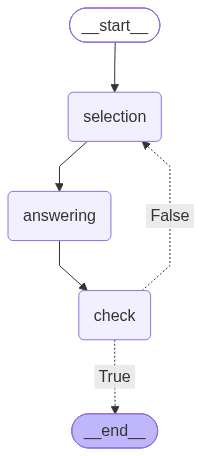

In [31]:
# 복잡한 그래프일수록 코드만으로 최종적인 그래프 형태를 파악하기가 어려워진다.
# 따라서 LangGraph에는 그래프 구조를 시각화해 표시하기 위한 기능이 내장되어 있다.
# compile 함수를 실행해 얻은 CompiledGraph 클래스 인스턴스의 get_graph 함수를 사용하면 그래프 구조 정보를 가져올 수 있고, 여기에 draw_png 함수를 호출하면 그래프 구조를 PNG 이미지로 가져올 수 있다.
from IPython.display import Image, display

display(Image(compiled.get_graph().draw_mermaid_png()))
# Image(compiled.get_graph().draw_png())